# FLIM data analysis - AFM manuscript - Nidda Saaed

This notebook contains the script which was used to perform a part of the FLIM (Fluorescence Lifetime Imaging Microscopy) data analysis,
presented in the AFM manuscript by first author Nidda Saaed, entitled

__"Electrically Enhanced Intraperitoneal Drug Delivery Resolved by Fluorescence Lifetime Imaging Microscopy"__

---


__FLIM data structure__
1. __Base folder [1]__  $\rightarrow$ This base folder contains a number of groups.
2. __Group subfolders [5]__ $\rightarrow$ Each group subfolder represents a drug administration method (PD or EMDA, Free DOX or DOX NPs, 6hrs or 24 hrs) and contains a number of FLIM analysis files associated with a sample.
3. __Samples [81/group]__   $\rightarrow$ Per sample, FLIM analysis returned an extensive set of ROI's (regions of interest) with according features, including coordinates and mean intensity. Data is saved as an Excel CSV file: rows=datapoints, columns=features.

__Overarching goal__

Present mean intensity and mean lifetime over depth within the tumor samples, retrieve insightful statistics on drug administration methods and compare their performances.

__Notebook overview__

    0. Import packages
    1. Input
    2. Support
    3. Process data
    4. Visualize

__How to use__

- Step 1: $\color{Green}{\text{Modify}}$ Input in section 1 if needed, otherwise $\color{Blue}{\text{Just run}}$
- Step 2: Run sections 0-3 or full notebook at once (double green arrow above)
- Step 3: Analyze dataset and generate plots in section 4.

## 0. Import packages
__--- $\color{Blue}{\text{Just run}}$ ---__

In [31]:
# importing packages and notebook settings
import numpy as np                                          # scientific computations
import matplotlib.pyplot as plt                             # plotting
import matplotlib.cm as cm                                  # colormaps
import matplotlib.colors as mcolors                         # colors
%matplotlib inline
import os                                                   # operating system
import pandas as pd                                         # dataframe
from scipy.signal import savgol_filter                      # Savitky-Golay filter (fit & smooth)
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib_scalebar.scalebar import ScaleBar           # scalebar
from pathlib import Path                                    # paths
from scipy.stats import binned_statistic_2d                 # 2D bin and associated stats
import re                                                   # regular expressions
from termcolor import colored                               # enable colored print text

from shapely.geometry import Polygon                        # polygons
from shapely.geometry import Point                          # point
from shapely import points, distance, LineString            # points, distance measurement, lines

from sklearn.neighbors import LocalOutlierFactor            # ML - local outlier estimation
from sklearn.preprocessing import StandardScaler            # ML - weighting scaler function
from sklearn.cluster import DBSCAN                          # ML - clustering datapoints
import alphashape


from openpyxl import Workbook                                           # Excel workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side  # related above
from openpyxl.utils import get_column_letter                            # related above


# --- backup imports --- #
import math                                                 # mathematical operations
import numpy.ma as ma                                       # masked arrays
from tqdm import tqdm                                       # progress bars
import copy                                                 # copy lists to preserve original data
import time                                                 # timer
from time import perf_counter                               # progress bar

## 1. Input

__--- $\color{Green}{\text{Modify}}$ ---__

### Define data structure
__--- $\color{Green}{\text{Modify}}$ ---__

In [32]:
# define absolute path to your base folder containing all FLIM data - we will call this our 'base'
base = r'S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\2026 Analysis FLIM\For python script testing'


# ----------------------------------------------------------------------------------- #
# --- don't change unless you expect other file extensions, group or sample names --- #
# ----------------------------------------------------------------------------------- #

# define possible extension of data files
excel_exts = {".xlsx", ".xls", ".xlsm", ".xlsb"}
csv_exts   = {".csv", ".tsv", ".txt"}
all_exts = excel_exts | csv_exts

# define conditions for relevant group selection (e.g. all groups start with a number
def group_conditions(group):
    C1 = group.startswith(('1','2','3','4','5'))    # condition: group name starts with digit in list [1, 2, 3, 4, 5] --> ('1','2','3','4','5')
    C2 = not group.endswith('.db')                  # condition: exclude database ('.db') folders
    conditions = [C1, C2]
    return all(conditions)

# define conditions for relevant sample selection (e.g. all sample files end on 'Labels')
def sample_conditions(sample):
    C1 = sample.lower().endswith("labels")
    conditions = [C1]
    return all(conditions)
# ----------------------------------------------------------------------------------- #

### Define features of interest (FOI)
__--- $\color{Green}{\text{Modify}}$ ---__

In [33]:
# put column names of input files according to features of interest 'foi' in this list underneath
foi = ['MeanInt', 'MeanTauPhase', 'CentroidX', 'CentroidY']         # default: ['MeanInt', 'MeanTauPhase', 'CentroidX', 'CentroidY']

### Define scale
__--- $\color{Green}{\text{Modify}}$ ---__

In [34]:
# pixel to µm scale based on GSlab metadata - depends on microscope acquisition settings
scale = 0.569   # default: 1px = 0.569µm

### Define depth interval

__--- $\color{Green}{\text{Modify}}$ ---__

In [35]:
depth_interval=100.0        # depth interval in unit: µm; default: 100

### Remove outliers

__--- $\color{Green}{\text{Modify}}$ ---__

In [36]:
# define if you want to automatically detect and remove outliers
rem_outliers = False         # (True/False); default: False

### Turn on/off plot & save

__--- $\color{Green}{\text{Modify}}$ ---__

In [37]:
plot = True                # visualize all plots directly in notebook if True;     default: False;    NB: time-consuming!
save_plot = True           # save all plots directly to pc folder if True;         default: False;    NB: time-consuming!

## 2. Support
__--- $\color{Blue}{\text{Just run}}$ ---__

Backbone of data processing.

Content:

    A. Read & collect data
    B. Scale coordinates
    C. Generate test dataset
    D. Sample scan direction
    E. Outliers
    F. Depth & isolines
    G. Aggregate dataframe
    H. Compare groups
    I. Dataframe to Excel
    J. Main function

#### A. Read & collect data

In [38]:
def find_files(FOLDER):
    valid_files = []
    for root, _, files in os.walk(FOLDER):
        for f in files:
            sample, ext = os.path.splitext(f)[0], os.path.splitext(f)[1].lower()
            if (ext in all_exts) and (sample_conditions(sample)):
                valid_files.append(os.path.join(root, f))
    return sorted(valid_files)

def collect_data(BASE, FOI):
    '''
    Input:
        - BASE: base path to your data
        - FOI: list of features of interest

    Output:
        - df: large dataframe containing all features of interest extracted from all tiles in specified folder
    '''

    # create large dataframe to collect all FOIs for chosen folder
    # df = pd.DataFrame(columns=['group', 'sample'] + FOI)

    # create empty list that will contain smaller dataframes
    dfs = []

    # create counter for size of samples
    n_samples = 0

    # print names of groups present in folder
    groups = [g for g in sorted(os.listdir(f'{BASE}')) if group_conditions(g)]
    n_groups = len(groups)

    # loop over groups
    for group in groups:
        # if group == 'Overview':
        #     continue
        # retrieve samples
        samples = find_files(FOLDER=f'{BASE}/{group}')  # find valid files
        n_samples += len(samples)     # update number of sections
        # loop over samples
        for sample in samples:
            ext = os.path.splitext(f'{sample}')[1].lower()
            if ext in excel_exts:
                # read in Excel file associated with sample
                df_sample = pd.read_excel(f'{sample}')
            elif ext in csv_exts:
                # read in CSV file associated with sample
                df_sample = pd.read_csv(f'{sample}')
            else:
                raise ValueError("-x- invalid extension data file (not csv or excel) -x-")
            # only extract columns from Excel file that are in your FOI
            df_sample_FOI = df_sample[FOI]


            # add metadata columns
            df_sample_FOI['group'] = group
            df_sample_FOI['sample'] = Path(sample).stem     # ensures base and extension is dropped out

            # add sample dataframe to list of dataframes 'dfs'
            dfs.append(df_sample_FOI)


    # print info
    print(f'~~~ All data has successfully been collected from your folder with base path: {BASE}.')
    print(f'~~~ This folder contains {n_groups} groups: {groups}')
    print(f'~~~ Total number of samples over all groups: {n_samples}')

    # add collection of all small sample dataframes 'dfs' in one comprehensive dataframe
    return pd.concat(dfs, ignore_index=True)

#### B. Scale coordinates

In [39]:
def px_to_µm(DF, X_COL, Y_COL, SCALE):
    """
    Convert xy-coordinates from pixel to µm units based on a given scale

    Input:
        - DF: dataframe containing xy-coordinates [unit: pixels]
        - X_COL: column name of X coordinate
        - Y_COL: column name of Y coordinate
        - SCALE: scaling factor (pixel to µm)

    Output:
        - NO EXPLICIT OUTPUT: scaled DF dataframe containing xy-coordinates [unit: µm]
    """
    # convert xy-coordinates to µm units based on scale
    DF[X_COL] = DF[X_COL] * SCALE
    DF[Y_COL] = DF[Y_COL] * SCALE
    print(f"~~~ coordinate units scaled from pixel to µm --> 1 px = {SCALE} µm")

#### C. Generate test dataset

__Boundary profiles__

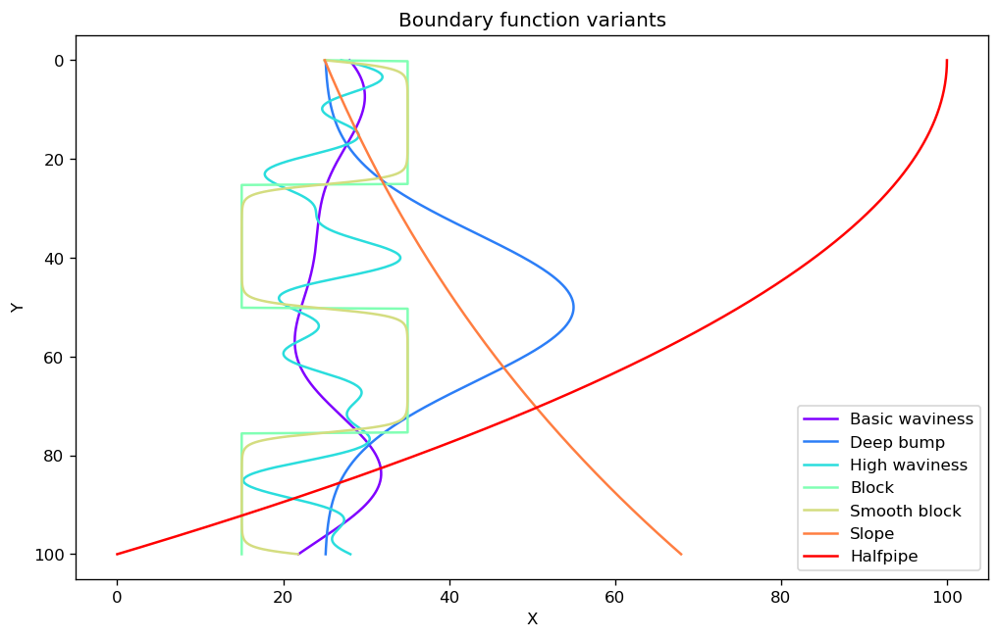

In [40]:
# different test edges for imaged sample
def boundary_func(y):
    # basic wavy curve
    return 25 + 5 * np.sin(y / 10) + 3 * np.cos(y / 7)

def boundary_func_bump(y):
    # curve with bump
    return 25 + 30 * np.exp(-((y - 50)**2) / (2 * 15**2))

def boundary_func_wavy(y):
    # very wavy curve
    return 25 + 5 * np.sin(y / 5) + 3 * np.sin(y / 2) + 2 * np.cos(y / 3)

def boundary_func_block(y):
    # block curve
    return 25 + 10 * np.sign(np.sin(y / 8))


def boundary_func_block_smooth(y):
    # smooth block curve
    return 25 + 10 * np.tanh(5 * np.sin(y / 8))

def boundary_func_slope(y):
    # smooth block curve
    return 25 * np.exp(y/100)

def boundary_func_halfpipe(y):
    # smooth block curve
    return 100 * (1 - (y/100)**2)

# plot curves


# functions list
funcs = [
    (boundary_func, "Basic waviness"),
    (boundary_func_bump, "Deep bump"),
    (boundary_func_wavy, "High waviness"),
    (boundary_func_block, "Block"),
    (boundary_func_block_smooth, "Smooth block"),
    (boundary_func_slope, "Slope"),
    (boundary_func_halfpipe, "Halfpipe"),
]


y = np.linspace(0, 100, 500)

plt.figure(figsize=(10,6), dpi=120)

# choose colormap
cmap = plt.get_cmap("rainbow")
colors = cmap(np.linspace(0, 1, len(funcs)))

for (f, label), c in zip(funcs, colors):
    plt.plot(f(y), y, label=label, color=c)


plt.gca().invert_yaxis()
plt.legend()
plt.title("Boundary function variants")
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

__generate test dataframe__

In [41]:
def generate_test_dataframe(
    n_points=2000,
    x_range=(0, 250),
    y_range=(0, 100),
    noise_level=2.0,
    random_seed=42,
    FLIP=False
):
    np.random.seed(random_seed)

    # ----------------------------------
    # 1. Generate random Y values
    # ----------------------------------
    Y = np.random.uniform(y_range[0], y_range[1], n_points)

    # ----------------------------------
    # 2. Generate X and I values only to the given SIDE of the chosen boundary
    # ----------------------------------
    X = np.zeros(n_points)
    I = np.zeros(n_points)
    HVL = 250   # half value layer

    I_0 = 100

    for i in range(n_points):

        # Define curved boundary (choose one from cell above)
        b = boundary_func_bump(Y[i])

        # sample X to the right of boundary
        X[i] = np.random.uniform(b, x_range[1])

        # add small randomness to emulate imperfect data
        #X[i] += np.random.normal(0, noise_level)

    for i in range(n_points):
        # decaying intensity over depth + random noise
        I[i] = I_0 *  ( 0.5**(X[i]/HVL) + np.random.uniform(-0.2, 0.2))

    if FLIP:
        # mirror dataset horizontally if FLIP=True
        X_mid = X.max()/2.0   # mirror line of datapoints
        dx = X-X_mid        # distance to mirror line
        X = X_mid - dx      # mirror datapoints


    # ----------------------------------
    # 4. create dataframe
    # ----------------------------------
    df = pd.DataFrame({
        "X": X,
        "Y": Y,
        "I": I
    })

    return df

In [42]:
# # Create dataset
# df = generate_test_dataframe(FLIP=True)
#
# plt.figure(figsize=(4, 3), dpi=300)
#
# # Scatter with intensity-based coloring
# sc = plt.scatter(
#     df["X"],
#     df["Y"],
#     c=df["I"],            # color = intensity
#     cmap="inferno",
#     s=5
# )
#
# # Add colorbar
# cbar = plt.colorbar(sc, fraction=0.03, pad=0.05)
# cbar.set_label("Intensity (I)")
#
# # Formatting
# plt.gca().set_aspect("equal")
# plt.xlim(0)
# plt.title("Synthetic test dataset")
#
# plt.show()


In [43]:
# plt.figure(figsize=(4,3), dpi=300)
# plt.scatter(df["X"], df["I"], marker='.', s=3)
# plt.title("intensity distribution test dataset")
# plt.xlabel("X-coordinate")
# plt.ylabel("intensity")
# plt.show()

#### D. Sample scan direction

In [44]:
# auxiliary function to detect sample scan direction
def detect_direction(DF, X_COL, Y_COL, INT_COL="MeanInt", N_BINS=30, PLOT=False, PRINT=False):
    '''
    Detect scan direction based on mean intensity distribution
    --> we expect intensity to drop over depth!

    Input:
        - DF: pandas dataframe of interest
        - X_COL: name of column containing x-coordinates of datapoints
        - Y_COL: name of column containing y-coordinates of datapoints
        - INT_COL: name of column containing intensity values of datapoints
        - N_BINS: number of bins to create 2D heatmap (default=20)
        - PLOT: plot heatmap (optional; default=False)
        - PRINT: print voting results (optional; default=False)

    Output:
        - direction ('left_to_right' or 'right_to_left') [type: string]
    '''

    # retrieve x-coords, y-coords and intensities per datapoint
    x = DF[X_COL].values
    y = DF[Y_COL].values
    i = DF[INT_COL].values

    # bin the data into a 2D grid
    heatmap, xedges, yedges, _ = binned_statistic_2d(
        x, y, i,
        statistic='mean',   # could also use 'sum', 'count', etc.
        bins=N_BINS
    )

    # go through y-bins and check LR or RL dominance
    LR_vote, RL_vote = 0, 0

    for row in heatmap.T:
        ints = row[~np.isnan(row)]
        # ensure row is not empty
        if ints.size > 0:
            if ints[0] > ints[-1]:
                LR_vote += 1
            elif ints[0] < ints[-1]:
                RL_vote += 1
    if PRINT:
        print(f'LR_vote: {LR_vote}, RL_vote: {RL_vote}')


    # Plot (OPTIONAL)
    if PLOT:
        plt.figure(figsize=(10, 6), dpi=100)
        plt.imshow(
            heatmap.T,
            origin='lower',
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            aspect='auto',
            cmap='coolwarm'
        )
        plt.colorbar(label='Intensity')
        plt.xlabel('X coordinate')
        plt.ylabel('Y coordinate')
        plt.title('Heatmap of FLIM intensity distribution')
        plt.show()


    # print voting info
    if PRINT:
        print(f'Voting results: LR: {LR_vote}, RL: {RL_vote}')
        if LR_vote > RL_vote:
            print('LR wins!')
        elif RL_vote > LR_vote:
            print('RL wins!')

        if np.max([LR_vote, RL_vote]) / float(N_BINS) < 0.66:
           print('voting might be ambiguous --> no 2/3 majority win!')

        # print(heatmap.T)  # print heatmap matrix (rows are read from bottom to top)


    # conclude scan direction based on votes (OPTIONAL print info)
    if LR_vote > RL_vote:
        return "left_to_right"
    elif RL_vote > LR_vote:
        return "right_to_left"
    else:
        print(f'[D] ~ Problem encountered: group: {DF['group'].unique()[0]} - sample: {DF['sample'].unique()[0]}')
        raise ValueError('[D] ~ Voting resulted in a tie! --> no clear scanning direction of sample')

In [45]:
def adjust_direction(DF, X_COL, Y_COL, INT_COL, N_BINS=30, PRINT=False, PLOT=False):
    '''
    Input:
    - DF: pandas dataframe of interest
    - X_COL: name of column containing x-coordinates of datapoints
    - Y_COL: name of column containing y-coordinates of datapoints
    - INT_COL: name of column containing intensity values of datapoints
    - N_BINS: number of bins to create 2D heatmap which is implicitly number of direction votes (default=30)
    - PRINT: print info on direction and mirror action (default=False)
    - PLOT: plot heatmap (default=False)

    Output:
    - no explicit output; implicit output = modified input dataframe DF (mirrored if needed)
    '''
    direction = detect_direction(DF, X_COL, Y_COL, INT_COL, N_BINS, PRINT=PRINT, PLOT=PLOT)
    if direction == "right_to_left":
        if PRINT:
            print('--- Mirror dataset')
        # mirror dataset horizontally
        X_max = DF[X_COL].max() # maximal x coordinate
        X_mid = X_max/2.0       # mirror line of datapoints
        dx = DF[X_COL]-X_mid    # distance to mirror line
        DF[X_COL] = X_mid - dx  # mirror datapoints

        direction_check = detect_direction(DF, X_COL, Y_COL, INT_COL, N_BINS)
        if direction_check == "left_to_right":
            if PRINT:
                print('[D] ~ mirror action successful')
        else:
            raise ValueError("[D] ~ mirror action failed")

#### E. Outliers

In [46]:
def first_bin(HEATMAP):
    counts = HEATMAP.T
    mask = HEATMAP.T > 0
    has_nonzero = mask.any(axis=1)
    first_nonzero_idx = np.where(has_nonzero, mask.argmax(axis=1), -1)
    bool_matrix = np.zeros_like(counts, dtype=bool)
    valid_rows = first_nonzero_idx >= 0
    bool_matrix[np.arange(len(counts))[valid_rows], first_nonzero_idx[valid_rows]] = True
    return bool_matrix


def find_bin(X, Y, X_EDGES, Y_EDGES):
    col = np.searchsorted(X_EDGES, X, side="left") - 1
    row = np.searchsorted(Y_EDGES, Y, side="left") - 1
    row = [0 if r < 0 else r for r in row]
    col = [0 if c < 0 else c for c in col]
    return row, col


def is_in_true_bin(X, Y, X_EDGES, Y_EDGES, BOOL_MATRIX):
    row, col = find_bin(X, Y, X_EDGES, Y_EDGES)
    # print(f'row: {row}, col: {col}')
    # print(f'min_row: {np.min(row)}, min_col: {np.min(col)}')
    # print(f'max_row: {np.max(row)}, max_col: {np.max(col)}')

    # Check bounds
    if (np.any(row) < 0 or np.any(row) >= BOOL_MATRIX.shape[0] or
        np.any(col) < 0 or np.any(col) >= BOOL_MATRIX.shape[1]):
        raise ValueError('[4E] ~ Problem with find_bin function: one or more bin(s) out of bounds!')

    return BOOL_MATRIX[row, col]

In [47]:
def detect_outliers(DF, X_COL, Y_COL, INT_COL, BINS=30, PLOT=False, SAVE_PATH=None):
    # combine features
    features = DF[[X_COL, Y_COL, INT_COL]].values

    # get group and sample names to include in title of figure
    g = DF['group'].unique()[0]
    s = DF['sample'].unique()[0]

    # scale features
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)

    # CONDITION 1: local outlier estimation
    lof = LocalOutlierFactor(n_neighbors=50, metric='euclidean')
    labels = lof.fit_predict(features_scaled)
    C1 = (labels == -1)

    # CONDITION 2: outliers should have intensity below specified percentage of max intensity
    th = 0.8 * np.max(DF[INT_COL].values)  # threshold intensity     # if you want to work with percentile --> np.percentile(DF[INT_COL].values, 90)
    C2 = (DF[INT_COL] < th)

    # CONDITION 3: outliers only assumed to exist within boundary region (first bin not nan)
    # bin the data into a 2D grid
    heatmap, xedges, yedges, _ = binned_statistic_2d(
        DF[X_COL].values, DF[Y_COL].values, DF[INT_COL].values,
        statistic='count',
        bins=BINS)

    bool_matrix = first_bin(HEATMAP=heatmap)
    C3 = (is_in_true_bin(X=DF[X_COL].values, Y=DF[Y_COL].values, X_EDGES=xedges, Y_EDGES=yedges, BOOL_MATRIX=bool_matrix))

    # print(f'counts per bin: {heatmap.T}')
    # print(f'xedges: {xedges}' + '\n' + f'yedges: {yedges}')

    # separate DF in clean data and outliers based on conditions C1, C2, C3
    mask = C1 & C2 & C3
    DF_outliers = DF[mask]
    DF_clean = DF[~mask]

    if SAVE_PATH or PLOT:
        plt.figure()
        plt.scatter(DF[X_COL], DF[Y_COL], c=DF[INT_COL], cmap='coolwarm', s=10, alpha=1)
        plt.scatter(DF_outliers[X_COL], DF_outliers[Y_COL], edgecolors='red', s=30, marker='o', facecolors='none', label=f'outliers [{DF_outliers.shape[0]}/{DF.shape[0]}]')
        plt.legend(loc='upper right')
        plt.title(f"Outliers - {g}: {s}")
        if SAVE_PATH:
            plt.savefig(f'{SAVE_PATH}\\outliers.png', dpi=300)
        if PLOT:
            plt.show()

    return DF_clean, DF_outliers

#### F. Depth & isolines

In [48]:
def compute_depth(
    DF,
    X_COL,
    Y_COL,
    INT_COL,
    N_Y_BINS=50,
    SMOOTH_WINDOW=21,
    SMOOTH_POLY=2,
    DEPTH_INTERVAL=50.0,
    GRID_SIZE=1000,
    SAVE_PATH=None,
    PLOT=False,
    REM_OUTLIERS=False,
):
    """
    Input:
        - DF: pandas dataframe of interest
        - X_COL: name of column containing x-coordinates of datapoints
        - Y_COL: name of column containing y-coordinates of datapoints
        - INT_COL: name of column containing intensity values of datapoints
        - N_Y_BINS: number of bins in y-direction to detect boundary of sample
        - SMOOTH_WINDOW: smoothing window size (default=21)
        - SMOOTH_POLY: smoothing polynomial order (default=2)
        - DEPTH_INTERVAL: depth interval [px] (default=50)
        - GRID_SIZE: grid size (default=1000)

    Output:
        - cleaned dataframe (without outliers)
    """

    DF = DF.copy()

    # --------------------------------------------------
    # 0. outlier detection (if REM_OUTLIERS=True)
    # --------------------------------------------------
    if REM_OUTLIERS:
        DF_clean, DF_outliers = detect_outliers(DF, X_COL, Y_COL, INT_COL, SAVE_PATH=SAVE_PATH, PLOT=PLOT);
    else:
        DF_clean = DF.copy()

    # --------------------------------------------------
    # 1. boundary extraction
    # --------------------------------------------------
    y_bins = np.linspace(DF_clean[Y_COL].min(), DF_clean[Y_COL].max(), N_Y_BINS)
    DF_clean["y_bin"] = pd.cut(DF_clean[Y_COL], bins=y_bins, labels=False)

    grouped_x = DF_clean.groupby("y_bin")[X_COL]

    boundary_x = grouped_x.quantile(0.005)

    y_centers = 0.5 * (y_bins[:-1] + y_bins[1:])
    boundary = boundary_x.reset_index()
    boundary[Y_COL] = boundary["y_bin"].map(lambda i: y_centers[int(i)])

    boundary = boundary.dropna().sort_values(Y_COL)

    bx = boundary[X_COL].values
    by = boundary[Y_COL].values

    # --------------------------------------------------
    # 2. smoothing
    # --------------------------------------------------
    if len(bx) >= SMOOTH_WINDOW:
        bx = savgol_filter(bx, SMOOTH_WINDOW, SMOOTH_POLY)
        by = savgol_filter(by, SMOOTH_WINDOW, SMOOTH_POLY)

    # --------------------------------------------------
    # 3. Polygon and left boundary
    # --------------------------------------------------

    # left boundary as line
    left_boundary = LineString(np.column_stack([bx, by]))

    # polygon
    xmin, xmax = DF_clean[X_COL].min(), DF_clean[X_COL].max()
    ymin, ymax = DF_clean[Y_COL].min(), DF_clean[Y_COL].max()

    # ensure boundary runs top -> bottom
    order = np.argsort(by)[::-1]
    bx_ord = bx[order]
    by_ord = by[order]

    poly_x = np.concatenate([
        bx_ord,
        [xmax, xmax]
    ])

    poly_y = np.concatenate([
        by_ord,
        [ymin, ymax]
    ])

    poly = Polygon(np.column_stack([poly_x, poly_y])).buffer(0)

    # # --------------------------------------------------
    # # 1. DBSCAN: keep largest cluster
    # # --------------------------------------------------
    #
    # pts = DF_clean[[X_COL, Y_COL]].values
    #
    # db = DBSCAN(
    #     eps=50,             # radius in which to scan for neighbours; default=50
    #     min_samples=3       # minimum number of neighbours to consider point as part of cluster; default=3
    # )
    #
    # labels = db.fit_predict(pts)
    #
    # valid = labels >= 0
    #
    # pts_valid = pts[valid]
    # labels_valid = labels[valid]
    #
    # largest_cluster = (
    #     np.bincount(labels_valid)
    #     .argmax()
    # )
    #
    # pts_cluster = pts_valid[
    #     labels_valid == largest_cluster
    # ]
    #
    # # --------------------------------------------------
    # # 2. Alpha shape (concave hull)
    # # --------------------------------------------------
    #
    # alpha = 0.05         # degree of detail of concave hull: lower values = less detail, default=0.05
    #
    # shape = alphashape.alphashape(
    #     pts_cluster,
    #     alpha
    # )
    #
    # if shape.geom_type == "MultiPolygon":
    #     shape = max(
    #         shape.geoms,
    #         key=lambda p: p.area
    #     )
    #
    # poly = shape
    #
    # # --------------------------------------------------
    # # 3. Extract left boundary
    # # --------------------------------------------------
    #
    # boundary_coords = np.asarray(
    #     poly.exterior.coords
    # )
    #
    # # find top and bottom points of polygon
    # top_idx = np.argmax(boundary_coords[:,1])
    # bottom_idx = np.argmin(boundary_coords[:,1])
    #
    # # n = len(boundary_coords)
    #
    # # path 1 along polygon
    # if top_idx < bottom_idx:
    #     arc1 = boundary_coords[top_idx:bottom_idx+1]
    #     arc2 = np.vstack([
    #         boundary_coords[bottom_idx:],
    #         boundary_coords[:top_idx+1]
    #     ])
    # # path 2 along polygon
    # else:
    #     arc1 = np.vstack([
    #         boundary_coords[top_idx:],
    #         boundary_coords[:bottom_idx+1]
    #     ])
    #     arc2 = boundary_coords[bottom_idx:top_idx+1]
    #
    # # select leftmost branch of polygon ==> left boundary of sample
    # if arc1[:,0].mean() < arc2[:,0].mean():
    #     left_arc = arc1
    # else:
    #     left_arc = arc2
    #
    # # # optional smoothing
    # # if len(left_arc) > SMOOTH_WINDOW:
    # #
    # #     win = min(
    # #         SMOOTH_WINDOW,
    # #         len(left_arc)//2*2-1
    # #     )
    # #
    # #     left_arc[:,0] = savgol_filter(
    # #         left_arc[:,0],
    # #         win,
    # #         SMOOTH_POLY
    # #     )
    # #
    # #     left_arc[:,1] = savgol_filter(
    # #         left_arc[:,1],
    # #         win,
    # #         SMOOTH_POLY
    # #     )
    #
    # by = left_arc[:, 1]
    #
    # ymin = DF_clean[Y_COL].min()
    # ymax = DF_clean[Y_COL].max()
    #
    # margin = 0.2*DEPTH_INTERVAL
    #
    # # middle of sample
    # ymid = 0.5 * (ymin + ymax)
    #
    # # point on arc closest to middle
    # mid_idx = np.argmin(np.abs(by - ymid))
    #
    # # --------------------------------------------------
    # # walk towards top
    # # --------------------------------------------------
    #
    # upper_idx = len(by) - 1
    #
    # for i in range(mid_idx, len(by)):
    #     if by[i] >= ymax - margin:
    #         upper_idx = i
    #         break
    #
    # # --------------------------------------------------
    # # walk towards bottom
    # # --------------------------------------------------
    #
    # lower_idx = 0
    #
    # for i in range(mid_idx, -1, -1):
    #     if by[i] <= ymin + margin:
    #         lower_idx = i
    #         break
    #
    # # --------------------------------------------------
    # # keep only reliable middle segment
    # # --------------------------------------------------
    #
    # left_arc = left_arc[lower_idx:upper_idx + 1]
    #
    # bx = left_arc[:, 0]
    # by = left_arc[:, 1]
    #
    # left_boundary = LineString(left_arc)


    # --------------------------------------------------
    # 4. depth to boundary per datapoint
    # --------------------------------------------------
    pts = points(DF_clean[X_COL].values, DF_clean[Y_COL].values)                # xy-coordinates of datapoints

    dist_pts = distance(pts, left_boundary)                                     # compute nearest distance between datapoints and sample boundary

    DF_clean['depth'] = dist_pts                                                # add dataframe column 'depth'
    DF_clean = DF_clean[DF_clean['depth'] >= -0.5 * DEPTH_INTERVAL].dropna()    # filter out points too far out of sample boundary

    # regions
    region = np.floor(DF_clean['depth'].values / DEPTH_INTERVAL).astype(int)    # region 0: [0 - DEPTH_INTERVAL],...,region n: [n*DEPTH_INTERVAL - (n+1)*DEPTH_INTERVAL]
    region[region < 0] = 0                                                      # include points left of boundary that still are close enough to be considered as part of sample
    DF_clean['region'] = region                                                 # add region to dataframe

    # --------------------------------------------------
    # 5. grid for isolines
    # --------------------------------------------------
    x_grid = np.linspace(DF_clean[X_COL].min(), DF_clean[X_COL].max(), GRID_SIZE)
    y_grid = np.linspace(DF_clean[Y_COL].min(), DF_clean[Y_COL].max(), GRID_SIZE)
    Xg, Yg = np.meshgrid(x_grid, y_grid)

    from shapely import contains

    grid_pts = points(Xg.ravel(), Yg.ravel())

    # distance only to left boundary
    D = distance(grid_pts, left_boundary)

    # mask using polygon
    inside_grid = contains(poly, grid_pts)

    # reshape
    D = D.reshape(Xg.shape)
    inside_grid = inside_grid.reshape(Xg.shape)

    # keep only valid region (right of boundary)
    D[~inside_grid] = np.nan


    # isoline levels
    max_depth = np.nanmax(D)
    levels = np.arange(DEPTH_INTERVAL, max_depth + DEPTH_INTERVAL, DEPTH_INTERVAL)

    # --------------------------------------------------
    # 6. store everything
    # --------------------------------------------------
    DF_clean.attrs["boundary"] = {"bx": bx.tolist(), "by": by.tolist()}
    DF_clean.attrs["depth_interval"] = DEPTH_INTERVAL
    DF_clean.attrs["grid"] = {
    "Xg": Xg.tolist(),
    "Yg": Yg.tolist(),
    "D": D.tolist(),
    "levels": levels.tolist()
}


    return DF_clean

In [49]:
def compute_isolines(DF):
    grid = DF.attrs["grid"]
    return grid["Xg"], grid["Yg"], grid["D"], grid["levels"]

In [50]:
def plot_depth_isolines(DF, X_COL, Y_COL, INT_COL, SAVE_PATH=None):

    # compute isolines
    Xg, Yg, D, levels = compute_isolines(DF)

    # extract group & sample name to include in figure title
    g = DF['group'].unique()[0]
    s = DF['sample'].unique()[0]

    # initiate figure and axis
    fig, ax = plt.subplots(figsize=(7, 7))

    # datapoints colored by intensity
    sc = ax.scatter(
        DF[X_COL],
        DF[Y_COL],
        c=DF[INT_COL],
        cmap="coolwarm",
        alpha=0.4,
        s=15
    )

    # boundary (depth 0)
    bx = DF.attrs["boundary"]["bx"]
    by = DF.attrs["boundary"]["by"]

    ax.plot(bx, by, color="black", linewidth=2, label="Boundary (depth=0)")

    # isolines
    cs = ax.contour(
        Xg, Yg, D,
        levels=levels,
        colors="black",
        linestyles="dashed"
    )

    # optional: label contours
    manual_positions = []

    for seglist in cs.allsegs:
        for seg in seglist:
            if len(seg) < 20:
                continue
            mid_idx = len(seg) // 2
            manual_positions.append(tuple(seg[mid_idx]))

    clabels = ax.clabel(cs, manual=manual_positions, fontsize=10, fmt=lambda d: f"{int(d)}", )
    for txt in clabels:
        txt.set_bbox(dict(facecolor="white", edgecolor='none', pad=0))

    # colorbar (proper scaling)
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.1)
    cbar = plt.colorbar(sc, cax=cax)
    cbar.set_label("Intensity")

    # formatting
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    scalebar = ScaleBar(1, "µm", length_fraction=0.20, location='upper right')
    ax.add_artist(scalebar)
    ax.set_title(f"Depth and intensity - {g}: {s}")

    # save plot as png
    if SAVE_PATH:
        plt.savefig(f'{SAVE_PATH}\\isolines.png', dpi=300, bbox_inches="tight", transparent=False)

    plt.show()


In [51]:
def compute_region_stats(DF, INT_COL):
    stats = (
        DF[DF["region"] >= 0]
        .groupby("region")[INT_COL]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    return stats

In [52]:
def region_to_interval(DF, DEPTH_INTERVAL):
    # add intuitive column to output dataframe for region to depth layer translation (e.g. DEPTH_INTERVAL=50µm --> region 3 = [150µm - 200µm])
    DF['layer'] = (DF['region'] * DEPTH_INTERVAL).astype(int)

#### G. Aggregate dataframe

In [53]:
# Group all datapoints per sample and aggregate
def aggregate_per_sample(DF):
    return (
        DF
        .groupby(['group', 'sample', 'layer'])
        .agg(
            MeanInt_mean=('MeanInt', 'mean'),
            MeanInt_std=('MeanInt', 'std'),
            MeanInt_n=('MeanInt', 'count'),
            MeanTauPhase_mean=('MeanTauPhase', 'mean'),
            MeanTauPhase_std=('MeanTauPhase', 'std'),
            MeanTauPhase_n=('MeanTauPhase', 'count'),
        )
        .reset_index()
    )

# Group all datapoints per group and aggregate
def aggregate_per_group(DF):
    return (
        DF
        .groupby(['group', 'layer'])
        .agg(
            MeanInt_mean=('MeanInt', 'mean'),
            MeanInt_std=('MeanInt', 'std'),
            MeanInt_n=('MeanInt', 'count'),
            MeanTauPhase_mean=('MeanTauPhase', 'mean'),
            MeanTauPhase_std=('MeanTauPhase', 'std'),
            MeanTauPhase_n=('MeanTauPhase', 'count'),
        )
        .reset_index()
    )

#### H. Compare groups

In [54]:
def int_depth_profile(DF, X_MAX=None):
    """
    Input:
        - DF: aggregated pandas dataframe
        - X_MAX = max limit x-coordinate for plot

    Output:
        - fig: matplotlib figure --> comparison of intensity-depth profile between groups
    """
    fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

    # Encode groups as numeric for colorbar
    groups = sorted(DF['group'].unique())

    cmap = cm.viridis
    norm = mcolors.Normalize(vmin=0, vmax=len(groups)-1)
    print(norm)

    for i, g in enumerate(groups):
        x_coords = DF[(DF['group']==g)]['layer']
        y_coords = DF[(DF['group']==g)]['MeanInt_mean']
        y_errors = DF[(DF['group']==g)]['MeanInt_std']*1.96     # 1.96 * std_dev = 95% confidence level

        color = cmap(norm(i))

        # ax.errorbar(x=x_coords, y=y_coords, yerr=y_errrors,
        #         color=color,
        #         marker='o',
        #         markersize=5,
        #         capsize=6
        #            )
        ax.fill_between(x_coords, y_coords - y_errors, y_coords + y_errors, color=color, alpha=0.1, step='post')

        ax.plot(x_coords, y_coords,
                label=f'{g}',
                color=color,
                drawstyle='steps-post'
                )
        ax.legend(loc='lower right')
        ax.set_xlabel(f'Depth [µm]')
        ax.set_ylabel(f'Mean Intensity')
        ax.set_title(f'FLIM intensity over depth per drug administration method')
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
        if X_MAX is None:
            X_MAX = max(x_coords)
        ax.set_xlim(min(x_coords), X_MAX)

In [55]:
def lifetime_depth_profile(DF, X_MAX=None):
    """
    Input:
        - DF: pandas dataframe
        - X_MAX = limit x-coordinate for plot

    Output:
        - fig: matplotlib figure
    """
    fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

    # Encode groups as numeric for colorbar
    groups = sorted(DF['group'].unique())

    cmap = cm.viridis
    norm = mcolors.Normalize(vmin=0, vmax=len(groups)-1)
    print(norm)

    for i, g in enumerate(groups):
        x_coords = DF[(DF['group']==g)]['layer']
        y_coords = DF[(DF['group']==g)]['MeanTauPhase_mean']
        y_errors = DF[(DF['group']==g)]['MeanTauPhase_std']*1.96     # 1.96 * std_dev = 95% confidence level

        color = cmap(norm(i))

        # ax.errorbar(x=x_coords, y=y_coords, yerr=y_errrors,
        #         color=color,
        #         marker='o',
        #         markersize=5,
        #         capsize=6
        #            )
        ax.fill_between(x_coords, y_coords - y_errors, y_coords + y_errors, color=color, alpha=0.1, step='post')

        ax.plot(x_coords, y_coords,
                label=f'{g}',
                color=color,
                drawstyle='steps-post'
                )
        ax.legend(loc='lower right')
        ax.set_xlabel(f'Depth [µm]')
        ax.set_ylabel(f'Mean Lifetime')
        ax.set_title(f'FLIM lifetime over depth per drug administration method')
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
        if X_MAX is None:
            X_MAX = max(x_coords)
        ax.set_xlim(min(x_coords), X_MAX)

#### I. Dataframe to Excel

In [56]:
def build_output(DF, OUTPUT_PATH):
    wb = Workbook()
    ws = wb.active
    ws.title = "Group Data"

    TARGET_COLUMNS = [
        'group', 'sample', 'layer',
        'MeanInt_mean', 'MeanInt_std', 'MeanInt_n',
        'MeanTauPhase_mean', 'MeanTauPhase_std', 'MeanTauPhase_n'
    ]

    # Styles
    header_font = Font(name="Arial", bold=True, color="FFFFFF", size=11)
    file_font = Font(name="Arial", bold=True, size=10)
    data_font = Font(name="Arial", size=10)
    na_font = Font(name="Arial", size=10, italic=True, color="999999")

    header_fill = PatternFill("solid", start_color="2F5496")
    file_fill = PatternFill("solid", start_color="D9E1F2")
    alt_fill = PatternFill("solid", start_color="F2F7FF")

    center = Alignment(horizontal="center", vertical="center")
    left = Alignment(horizontal="left", vertical="center")

    thin = Side(style="thin", color="BFBFBF")
    border = Border(left=thin, right=thin, top=thin, bottom=thin)

    # Header row
    for col_idx, h in enumerate(TARGET_COLUMNS, 1):
        cell = ws.cell(row=1, column=col_idx, value=h)
        cell.font = header_font
        cell.fill = header_fill
        cell.alignment = center if col_idx > 1 else left
        cell.border = border

    ws.row_dimensions[1].height = 22

    # Data rows
    for row_idx, (_, row) in enumerate(DF.iterrows(), start=2):
        fill = file_fill if row_idx % 2 == 0 else alt_fill

        for col_idx, col_name in enumerate(TARGET_COLUMNS, start=1):
            val = row.get(col_name)
            cell = ws.cell(row=row_idx, column=col_idx)

            if val is not None:
                cell.value = val
                if isinstance(val, float):
                    cell.number_format = "0.000"
                elif isinstance(val, int):
                    cell.number_format = "0"
                cell.font = data_font
            else:
                cell.value = "N/A"
                cell.font = na_font

            cell.fill = fill
            cell.alignment = center if col_idx > 1 else left
            cell.border = border

        ws.row_dimensions[row_idx].height = 18

    # Column widths
    ws.column_dimensions["A"].width = 15
    for i in range(2, len(TARGET_COLUMNS) + 1):
        ws.column_dimensions[get_column_letter(i)].width = 20

    # Freeze header
    ws.freeze_panes = "A2"

    wb.save(OUTPUT_PATH)

#### J. Main function

In [57]:
def main(BASE, FOI, DEPTH_INTERVAL, SCALE=scale, PLOT=False, SAVE_PLOT = False, REM_OUTLIERS = False):

    # ----------------------------------------------- #
    #       user confirmation before execution        #
    # ----------------------------------------------- #
    proceed = input(f'Initiate FLIM data processing? (Y/N): ').strip().upper()
    if proceed != "Y":
        print(colored(f'=== Execution FLIM data processing aborted ===', 'red'))
        return None


    print(colored("=== Initiated FLIM data science ===\n", 'green'))

    # ----------------------------------------------- #
    #                collect FLIM data                #
    # ----------------------------------------------- #

    print("--- Collecting all data --- ")
    start1 = time.perf_counter()
    df = collect_data(BASE=BASE, FOI=FOI)
    px_to_µm(DF=df, X_COL='CentroidX', Y_COL='CentroidY', SCALE=SCALE)
    end1 = time.perf_counter()
    print(f"*** Data collected in: {end1 - start1:.3f} seconds ***\n")

    # ----------------------------------------------- #
    #     estimate execution time to inform user      #
    # ----------------------------------------------- #

    # retrieve number of samples
    n_samples = df['sample'].unique



    # ----------------------------------------------- #
    #         convert data in pandas dataframe        #
    # ----------------------------------------------- #

    print("--- Converting data in pandas dataframe ---")
    start2 = time.perf_counter()

    # initiate list for output subdataframes
    dfs = []

    # loop over groups in database
    for g in df['group'].unique():

        # loop over samples in group
        for s in df[df['group']==g]['sample'].unique():

            # create input subset 'df_sub_in' containing data from specific sample
            df_sub_in = df[(df['group']==g) & (df['sample']==s)]

            # adjust alignment of dataset if necessary
            adjust_direction(DF=df_sub_in, X_COL='CentroidX', Y_COL='CentroidY', INT_COL='MeanInt', PLOT=PLOT)

            # compute depth regions and add updated info to output subdataframe 'df_sub_out'; plotting (OPTIONAL)
            if SAVE_PLOT:
                path = f'{BASE}' + f'\\{g}\\{''.join(re.findall(r'\d', s))[:2]}'
            else:
                path = None
            df_sub_out = compute_depth(DF=df_sub_in, X_COL='CentroidX', Y_COL='CentroidY', INT_COL='MeanInt', SMOOTH_POLY=3, DEPTH_INTERVAL=DEPTH_INTERVAL, SAVE_PATH=path, PLOT=PLOT, REM_OUTLIERS=REM_OUTLIERS)#.drop(['y_bin'], axis=1)
            plt.close('all')

            # plot isolines and save figure (OPTIONAL)
            if PLOT:
                plot_depth_isolines(DF=df_sub_out, X_COL='CentroidX', Y_COL='CentroidY', INT_COL='MeanInt', SAVE_PATH=f'{BASE}' + f'\\{g}\\{''.join(re.findall(r'\d', s))[:2]}')
            plt.close('all')

            # add output subdataframe to list
            dfs.append(df_sub_out)

    # create full output dataframe 'df_out'
    print('------ Creating full dataframe')
    df_out = pd.concat(dfs, ignore_index=True)

    # add intuitive column to output dataframe for region to depth layer translation (e.g. region 3 = [150µm - 200µm])
    region_to_interval(DF=df_out, DEPTH_INTERVAL=DEPTH_INTERVAL)

    # aggregate dataframe per sample and depth layer
    print('------ Aggregating dataframe per sample and depth')
    df_per_sample = aggregate_per_sample(df_out)

    # aggregate dataframe per group and depth layer
    print('------ Aggregating dataframe per group and depth')
    df_per_group = aggregate_per_group(df_out)

    end2 = time.perf_counter()
    print(f"*** Data converted in: {end2 - start2:.3f} seconds ***\n")

    # ----------------------------------------------- #
    #         convert dataframe to Excel file         #
    # ----------------------------------------------- #
    print('--- Write data to Excel file ---')
    start3 = time.perf_counter()

    # write data to Excel file - per sample
    print('------ writing data to Excel file: per sample')
    build_output(DF=df_per_sample, OUTPUT_PATH=f'{BASE}' + '\\Overview\\' + 'Overview_per_sample.xlsx')

    # # write data to Excel file - per group
    # print('------ writing data to Excel file: per group')
    # build_output(DF=df_per_group, OUTPUT_PATH=f'{BASE}' + '\\Overview\\' + 'Overview_per_group.xlsx')

    # # write data to Excel file - all data
    # print('------ writing data to Excel file: all datapoints')
    # build_output(DF=df_out, OUTPUT_PATH=f'{BASE}' + '\\Overview\\' + 'Overview_per_datapoint.xlsx')
    end3 = time.perf_counter()
    print(f"*** Data written to Excel: {end3 - start3:.3f} seconds ***\n")


    # Convert total elapsed time to minutes and seconds
    elapsed = end3 - start1
    minutes, remainder = divmod(elapsed, 60)
    seconds = remainder

    print(colored(f'\n=== Completed FLIM data science ===\n Execution time: {int(minutes)}m {seconds:.2f}s', 'green'))

    # return output and aggregated dataframe
    return df_out, df_per_sample, df_per_group

## 3. Process data

__--- $\color{Blue}{\text{Just run}}$ ---__

Double-check your input parameters before execution!

=== Initiated FLIM data science ===

--- Collecting all data --- 
~~~ All data has successfully been collected from your folder with base path: S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\2026 Analysis FLIM\For python script testing.
~~~ This folder contains 5 groups: ['1 PD_DOXNPs_6hrs', '2 EMDA_DOXNPs_6hrs', '3 EMDA_DOXNPs_24hrs', '4 PD_FreeDOX_6hrs', '5 EMDA_FreeDOX_6hrs']
~~~ Total number of samples over all groups: 44
~~~ coordinate units scaled from pixel to µm --> 1 px = 0.569 µm
*** Data collected in: 8.196 seconds ***

--- Converting data in pandas dataframe ---


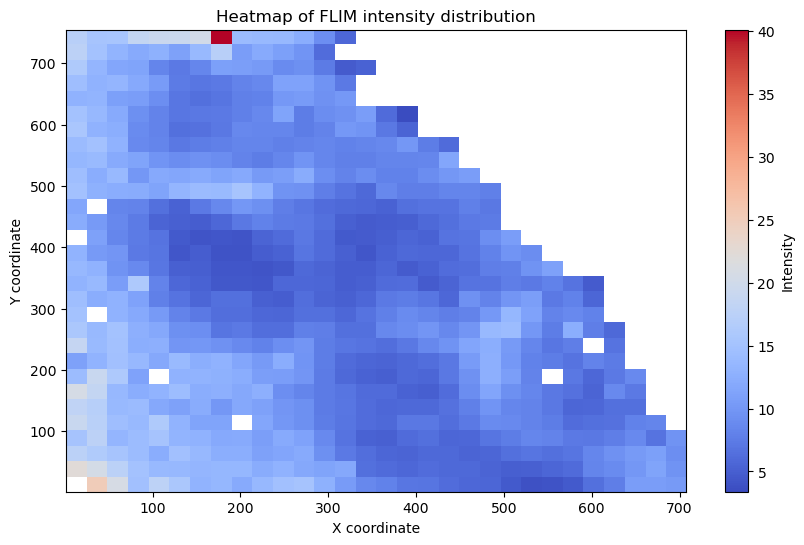

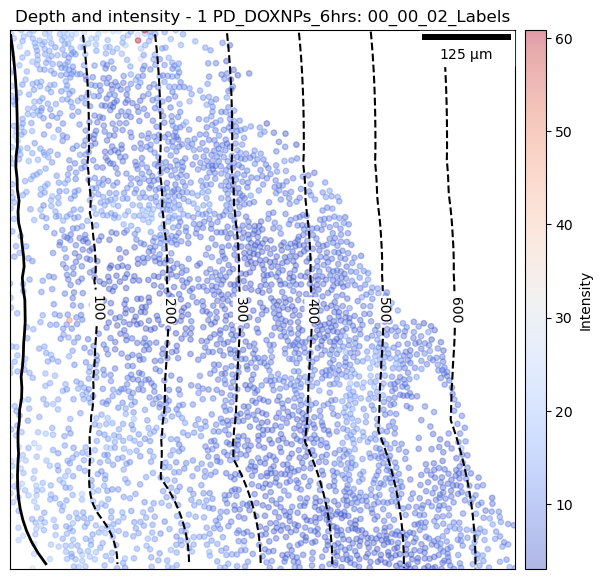

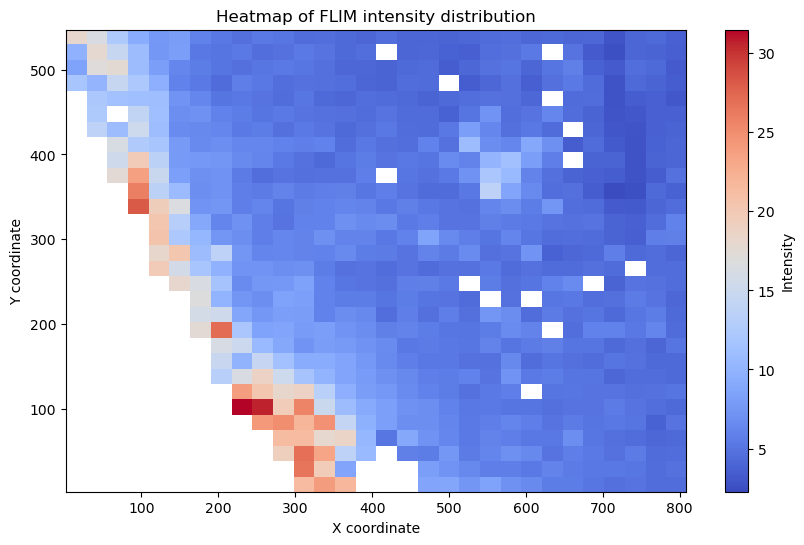

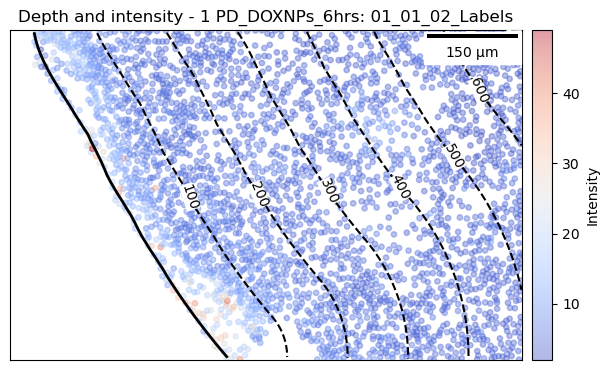

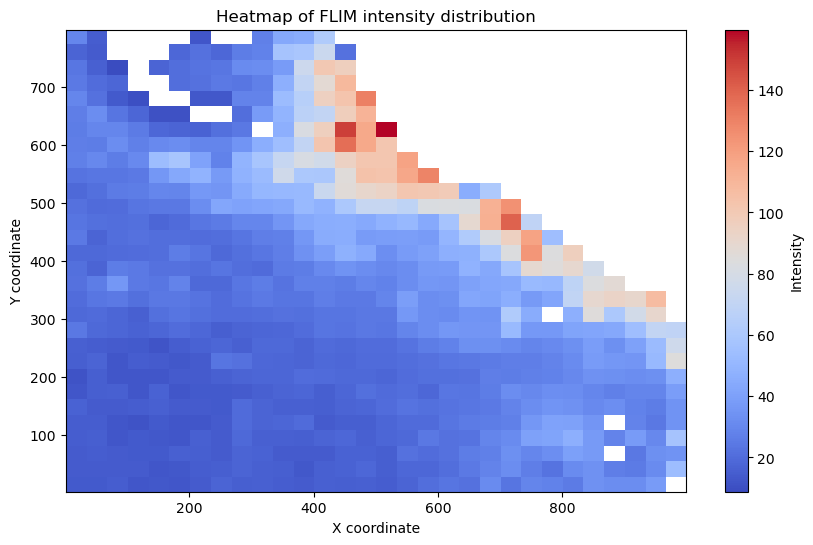

...

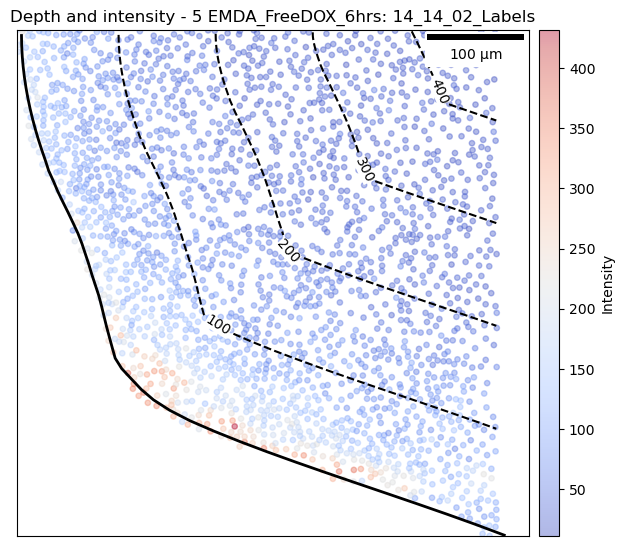

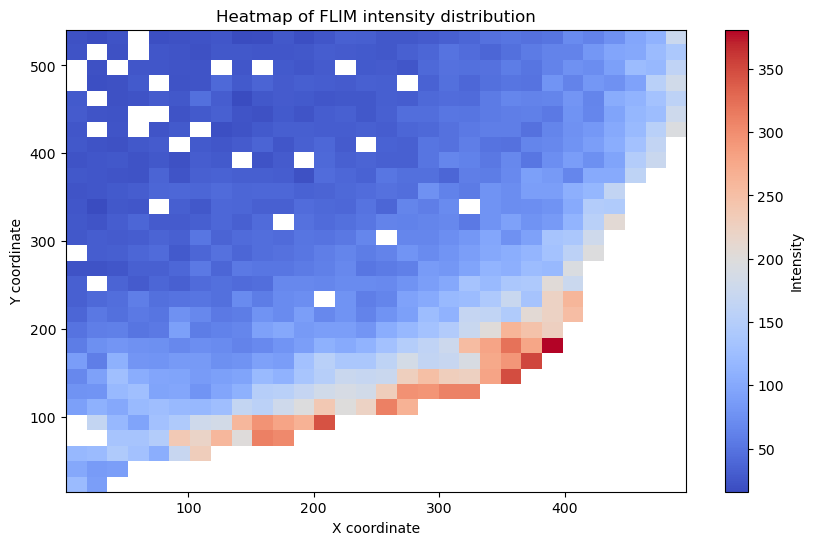

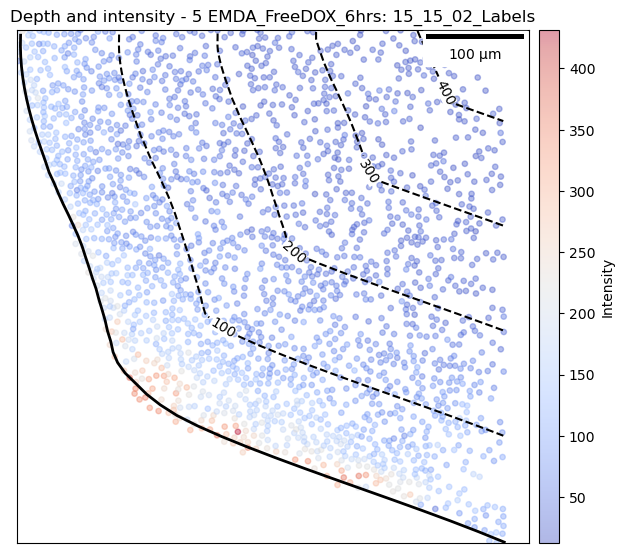

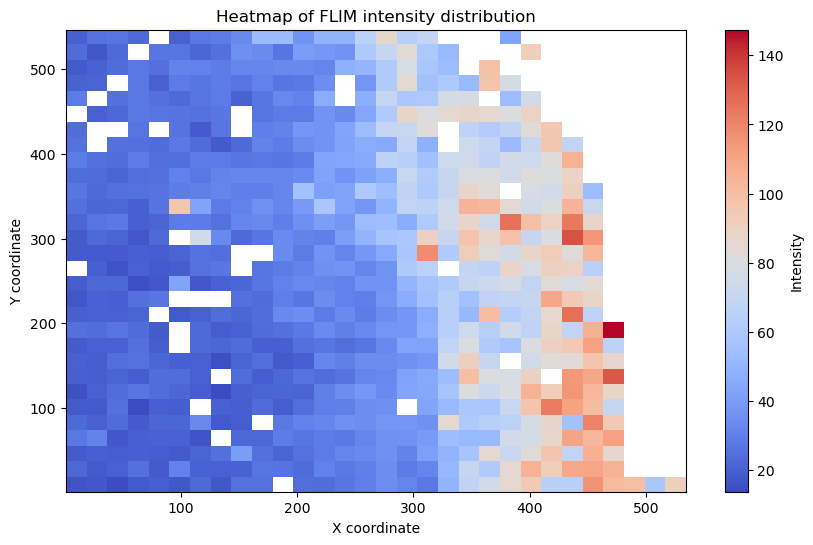

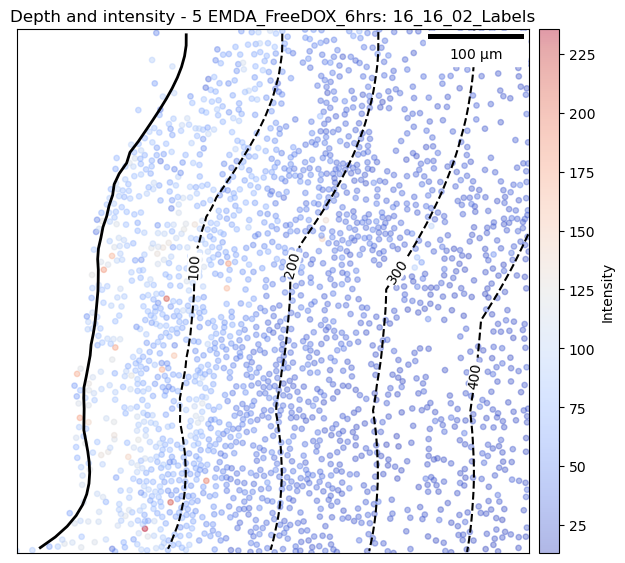

------ Creating full dataframe
------ Aggregating dataframe per sample and depth
------ Aggregating dataframe per group and depth
*** Data converted in: 703.237 seconds ***

--- Write data to Excel file ---
------ writing data to Excel file: per sample
*** Data written to Excel: 0.996 seconds ***


=== Completed FLIM data science ===
 Execution time: 11m 52.43s


In [58]:
# --- don't change directly --- #
df_out, df_per_sample, df_per_group = main(BASE=base, FOI=foi, SCALE=scale, DEPTH_INTERVAL=depth_interval, PLOT=plot, SAVE_PLOT=save_plot, REM_OUTLIERS=rem_outliers)

## 4. Visualize

__--- $\color{Blue}{\text{Just run}}$ ---__

In [59]:
df_out

,MeanInt,MeanTauPhase,CentroidX,CentroidY,group,sample,y_bin,depth,region,layer
0,14.7419,1.4477,90.620875,5.295398,1 PD_DOXNPs_6hrs,00_00_02_Labels,0.0,39.500520,0,0
1,18.1322,1.4516,97.217235,4.672969,1 PD_DOXNPs_6hrs,00_00_02_Labels,0.0,46.126155,0,0
2,16.4242,1.4073,106.661610,5.368856,1 PD_DOXNPs_6hrs,00_00_02_Labels,0.0,55.482448,0,0
3,11.0571,1.3720,150.923210,2.771827,1 PD_DOXNPs_6hrs,00_00_02_Labels,0.0,99.819139,0,0
4,13.5890,1.3190,227.841654,2.579960,1 PD_DOXNPs_6hrs,00_00_02_Labels,0.0,176.656468,1,100
...,...,...,...,...,...,...,...,...,...,...
150587,32.2276,1.3547,495.121950,545.423769,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,48.0,318.586519,3,300
150588,44.0988,1.3958,317.422283,545.713163,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,48.0,140.937744,1,100
150589,33.9072,1.4865,377.565811,546.421852,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,48.0,201.074625,2,200
150590,54.7037,1.4361,309.119094,546.134621,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,48.0,132.655876,1,100


In [60]:
df_per_sample

,group,sample,layer,MeanInt_mean,MeanInt_std,MeanInt_n,MeanTauPhase_mean,MeanTauPhase_std,MeanTauPhase_n
0,1 PD_DOXNPs_6hrs,00_00_02_Labels,0,13.200959,3.950089,547,1.425078,0.096120,547
1,1 PD_DOXNPs_6hrs,00_00_02_Labels,100,9.819611,4.953328,591,1.394246,0.165005,591
2,1 PD_DOXNPs_6hrs,00_00_02_Labels,200,8.416117,2.457144,631,1.352519,0.157510,631
3,1 PD_DOXNPs_6hrs,00_00_02_Labels,300,6.489447,1.556578,625,1.254892,0.192627,625
4,1 PD_DOXNPs_6hrs,00_00_02_Labels,400,7.952970,2.487694,562,1.114940,0.234115,562
...,...,...,...,...,...,...,...,...,...
305,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,0,81.748880,24.520077,597,1.291897,0.081498,597
306,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,100,49.435499,19.668947,632,1.390972,0.079479,632
307,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,200,29.363102,9.129184,497,1.445387,0.049385,497
308,5 EMDA_FreeDOX_6hrs,16_16_02_Labels,300,23.395928,8.307569,311,1.461603,0.064803,311


In [61]:
df_per_group

,group,layer,MeanInt_mean,MeanInt_std,MeanInt_n,MeanTauPhase_mean,MeanTauPhase_std,MeanTauPhase_n
0,1 PD_DOXNPs_6hrs,0,31.282330,27.208278,9692,1.311522,0.204441,9692
1,1 PD_DOXNPs_6hrs,100,15.823864,12.502266,6937,1.392077,0.136828,6937
2,1 PD_DOXNPs_6hrs,200,11.984179,8.902613,5717,1.382381,0.134639,5717
3,1 PD_DOXNPs_6hrs,300,10.461837,7.306690,4651,1.374814,0.154563,4651
4,1 PD_DOXNPs_6hrs,400,9.930333,5.757232,3836,1.355363,0.181320,3836
5,1 PD_DOXNPs_6hrs,500,9.157714,4.996142,2742,1.341615,0.229453,2742
6,1 PD_DOXNPs_6hrs,600,9.266633,4.782040,1795,1.388793,0.171723,1795
7,1 PD_DOXNPs_6hrs,700,9.951747,5.358977,1174,1.422462,0.112605,1174
8,1 PD_DOXNPs_6hrs,800,10.646383,4.904422,823,1.444722,0.108561,823
9,1 PD_DOXNPs_6hrs,900,7.581495,3.821502,264,1.434705,0.110920,264


### Comparison of groups

#### Depth-Intensity profile

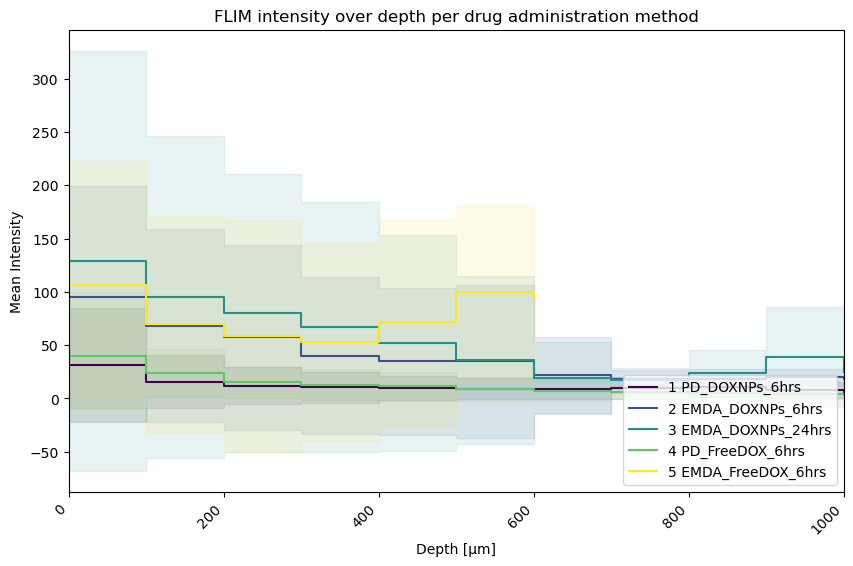

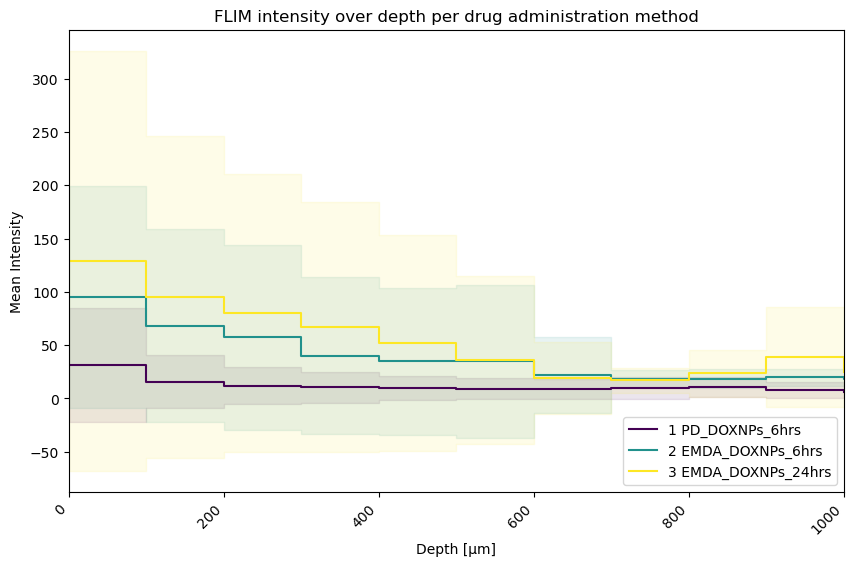

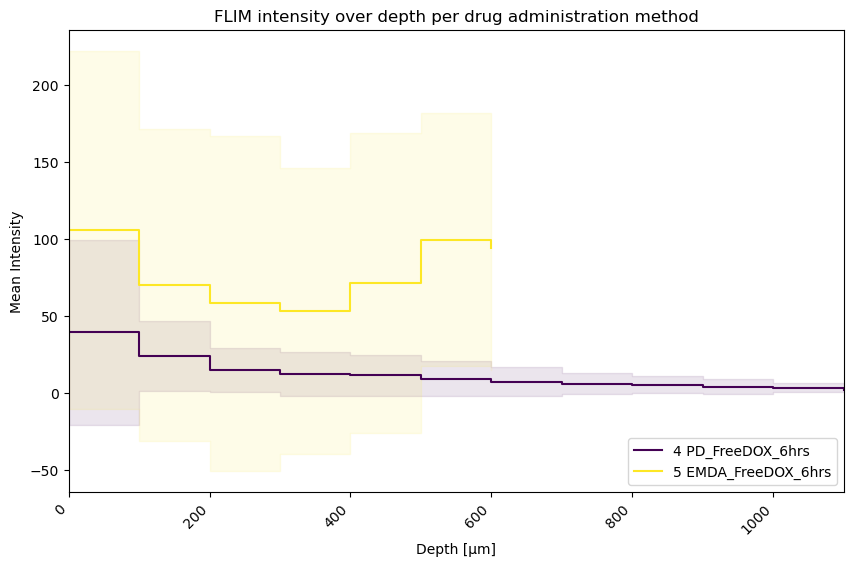

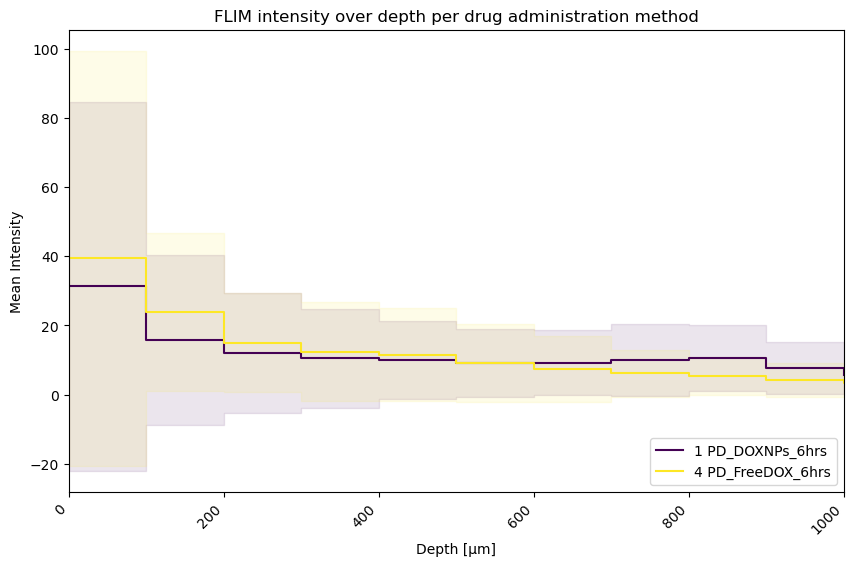

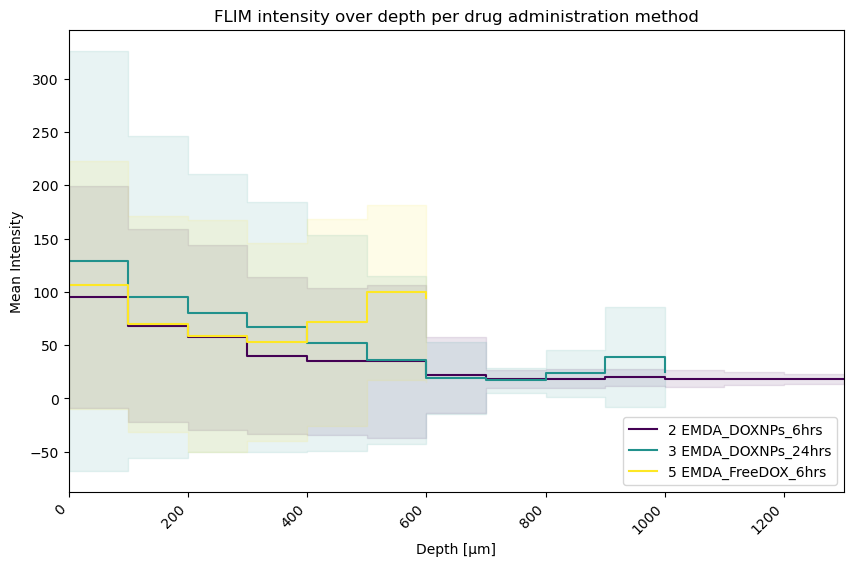

In [62]:
# subgroup selection
df_DOXNPs = df_per_group[df_per_group['group'].str.contains('DOXNPs')]      # subgroup selection: DOXNPs
df_FreeDOX = df_per_group[df_per_group['group'].str.contains('FreeDOX')]    # subgroup selection: FreeDOX
df_PD = df_per_group[df_per_group['group'].str.contains('PD')]              # subgroup selection: PD
df_EMDA = df_per_group[df_per_group['group'].str.contains('EMDA')]          # subgroup selection: EMDA

# plotting intensity profiles
int_depth_profile(DF=df_per_group)                                    # all groups
int_depth_profile(DF=df_DOXNPs)                                 # subgroup: DOXNPs
int_depth_profile(DF=df_FreeDOX)                                # subgroup: FreeDOX
int_depth_profile(DF=df_PD)                                     # subgroup: PD
int_depth_profile(DF=df_EMDA)                                   # subgroup: EMDA

#### Depth-Lifetime profile

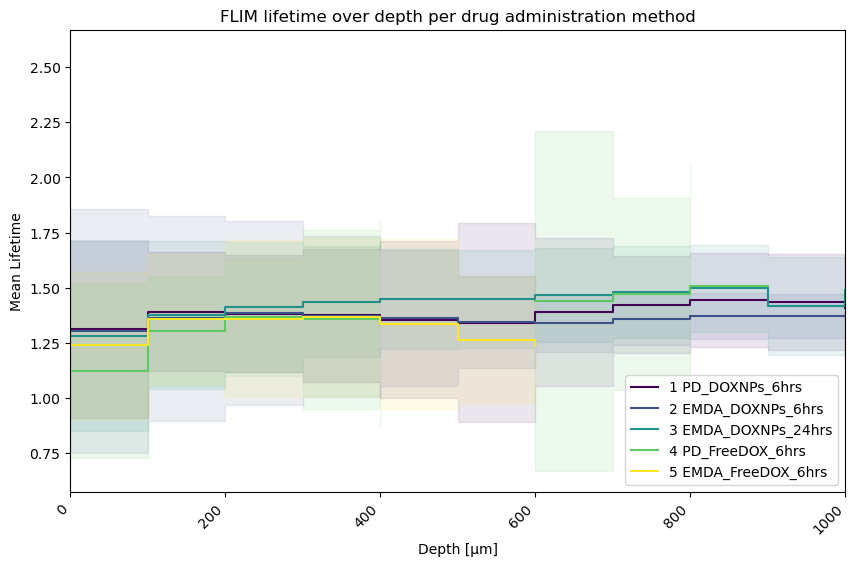

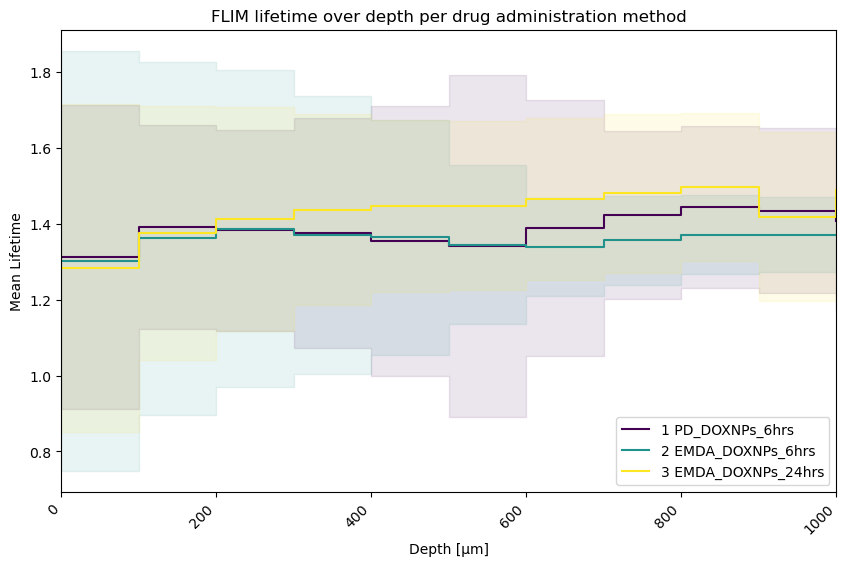

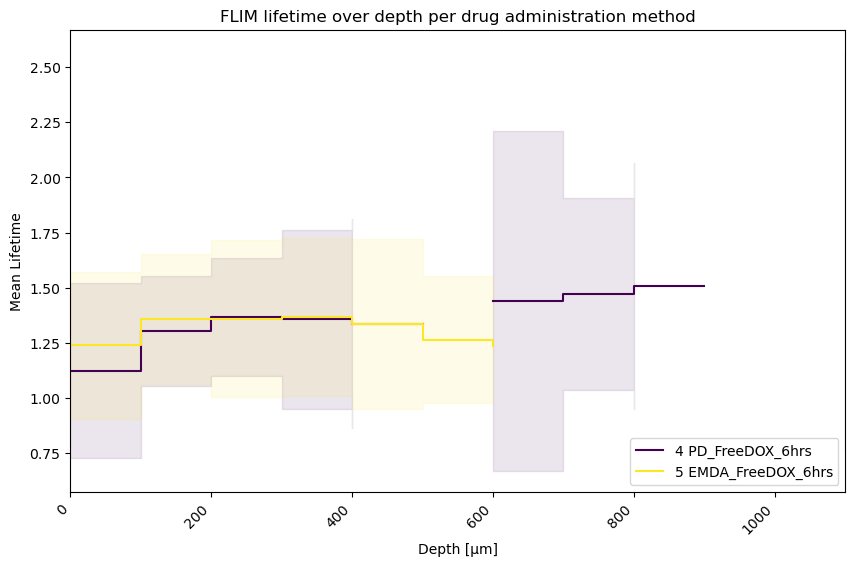

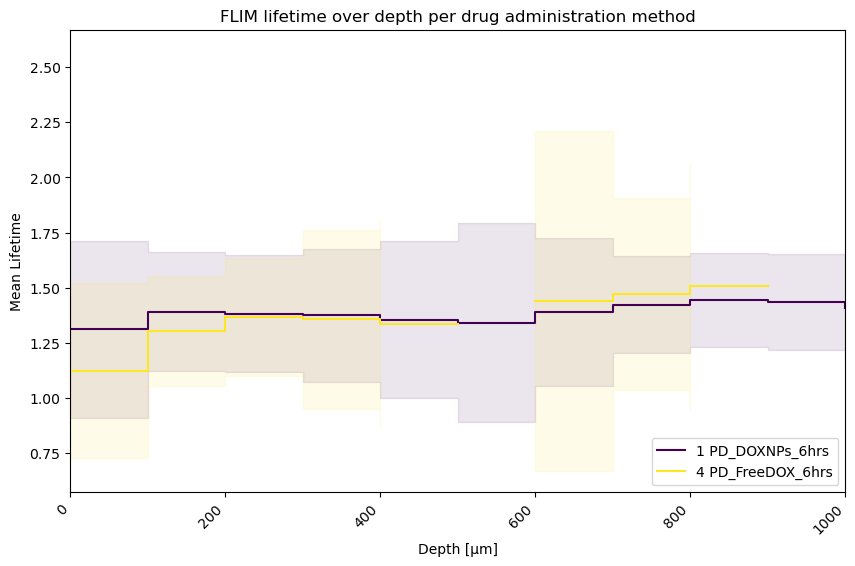

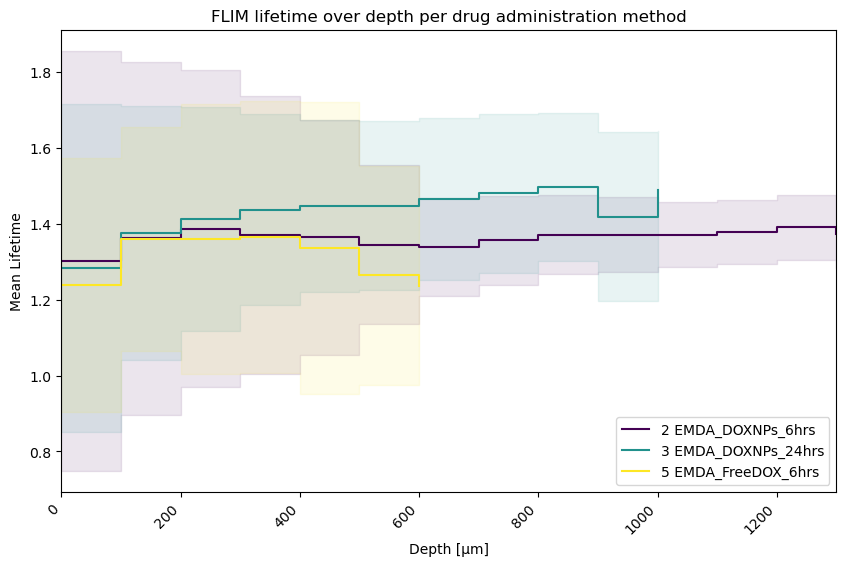

In [63]:
# subgroup selection - idem depth-intensity profile
# df_DOXNPs = df_agg[df_agg['group'].str.contains('DOXNPs')]      # subgroup selection: DOXNPs
# df_FreeDOX = df_agg[df_agg['group'].str.contains('FreeDOX')]    # subgroup selection: FreeDOX
# df_PD = df_agg[df_agg['group'].str.contains('PD')]              # subgroup selection: PD
# df_EMDA = df_agg[df_agg['group'].str.contains('EMDA')]          # subgroup selection: EMDA

# plotting intensity profiles
lifetime_depth_profile(DF=df_per_group)                                    # all groups
lifetime_depth_profile(DF=df_DOXNPs)                                 # subgroup: DOXNPs
lifetime_depth_profile(DF=df_FreeDOX)                                # subgroup: FreeDOX
lifetime_depth_profile(DF=df_PD)                                     # subgroup: PD
lifetime_depth_profile(DF=df_EMDA)                                   # subgroup: EMDA